# 📊 Comprehensive Experiment Results Analysis

This section provides a detailed analysis of all experiment results, including:
- Summary statistics across all experiments
- Comparative visualizations (tables, bar charts, spider plots)
- Statistical significance testing
- Key findings and insights

## 1. Load All Experiment Results

In [12]:
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from typing import Dict, List, Any
import warnings
warnings.filterwarnings('ignore')

# Set style
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 10

# Define path to results
RESULTS_PATH = Path(r"c:\Users\kamil\Documents\Kamil\HICSS extension\repo\C4-Modeler-LLM-Agents\data\results\enhanced_experiments")

# Load all final experiment results
experiment_files = {
    'Role Ablation': 'role_ablation_final_20251027_152900.json',
    'Interaction Order': 'interaction_order_final_20251028_130805.json',
    'Shared Memory': 'shared_memory_final_20251028_194748.json',
    'Role Diversity': 'role_diversity_final_20251028_222929.json',
    'Role Specialization': 'role_specialization_final_20251028_173315.json'
}

experiments_data = {}

for exp_name, filename in experiment_files.items():
    file_path = RESULTS_PATH / filename
    if file_path.exists():
        with open(file_path, 'r') as f:
            experiments_data[exp_name] = json.load(f)
        print(f"✓ Loaded {exp_name}")
    else:
        print(f"✗ Missing {exp_name}: {filename}")

print(f"\n📊 Loaded {len(experiments_data)} experiments")

✓ Loaded Role Ablation
✓ Loaded Interaction Order
✓ Loaded Shared Memory
✓ Loaded Role Diversity
✓ Loaded Role Specialization

📊 Loaded 5 experiments


## 2. Extract Key Metrics into DataFrames

In [15]:
# Extract aggregate results for all experiments
def extract_aggregate_metrics(exp_data: Dict) -> pd.DataFrame:
    """Extract aggregate metrics from experiment data"""
    rows = []
    
    # Prefer extracting from 'conditions' as it contains the most complete data
    if 'conditions' in exp_data:
        for condition_id, condition_data in exp_data['conditions'].items():
            row = {'condition': condition_id}
            
            # Get averages from condition summary
            summary = condition_data.get('condition_summary', {})
            averages = summary.get('averages', {})
            
            if not averages:
                continue
                
            # Extract ISO attributes
            # Map JSON keys to DataFrame columns
            iso_mapping = {
                'iso_functional_suitability': 'iso_functional',
                'iso_reliability': 'iso_reliability',
                'iso_performance_efficiency': 'iso_performance',
                'iso_maintainability': 'iso_maintainability',
                'iso_security': 'iso_security',
                'iso_usability': 'iso_usability',
                'iso_compatibility': 'iso_compatibility'
            }
            
            for json_key, df_col in iso_mapping.items():
                if json_key in averages:
                    row[df_col] = averages[json_key]
            
            # Extract ATAM
            if 'atam_responsiveness' in averages:
                row['atam_responsiveness'] = averages['atam_responsiveness']
            
            # Extract Soundness/Quality
            if 'soundness_abstraction_coherence' in averages:
                # Use abstraction coherence as a proxy for C4 quality if explicit score missing
                row['c4_quality'] = averages['soundness_abstraction_coherence'] * 5 # Scale to 0-5
            
            # Calculate ISO overall
            iso_values = [row[k] for k in row.keys() if k.startswith('iso_')]
            if iso_values:
                row['iso_overall'] = np.mean(iso_values)
            
            rows.append(row)
            
    # Fallback to aggregate_results if conditions not found (legacy support)
    elif 'aggregate_results' in exp_data:
        agg = exp_data['aggregate_results']
        cond_comp = agg.get('condition_comparison', {})
        
        if cond_comp:
            first_metric = list(cond_comp.values())[0]
            conditions = list(first_metric.keys())
            
            for condition_id in conditions:
                row = {'condition': condition_id}
                
                for iso_attr in ['ISO_Functional_Suitability', 'ISO_Reliability', 'ISO_Performance_Efficiency',
                                'ISO_Maintainability', 'ISO_Security', 'ISO_Usability', 'ISO_Compatibility']:
                    if iso_attr in cond_comp and condition_id in cond_comp[iso_attr]:
                        row[iso_attr.lower().replace('iso_', 'iso_').replace('_efficiency', '')] = cond_comp[iso_attr][condition_id]['mean']
                
                if 'ATAM_Scenario_Responsiveness' in cond_comp:
                    row['atam_responsiveness'] = cond_comp['ATAM_Scenario_Responsiveness'][condition_id]['mean']
                
                iso_keys = [k for k in row.keys() if k.startswith('iso_')]
                if iso_keys:
                    row['iso_overall'] = np.mean([row[k] for k in iso_keys])
                
                rows.append(row)
    
    return pd.DataFrame(rows)

# Extract metrics for all experiments
all_metrics = []

for exp_name, exp_data in experiments_data.items():
    df = extract_aggregate_metrics(exp_data)
    if not df.empty:
        df['experiment'] = exp_name
        all_metrics.append(df)
        print(f"✓ {exp_name}: {len(df)} conditions")

# Combine all metrics
if all_metrics:
    metrics_df = pd.concat(all_metrics, ignore_index=True)
    
    # Fill missing values with 0
    metrics_df = metrics_df.fillna(0)
    
    print(f"\n📊 Total: {len(metrics_df)} conditions across {len(all_metrics)} experiments")
    print(f"Columns: {list(metrics_df.columns)}")
    
    # Display sample to verify
    print("\nSample Data (First 3 rows):")
    print(metrics_df[['experiment', 'condition', 'iso_functional', 'iso_performance', 'iso_overall']].head(3))
else:
    print("⚠️ No metrics extracted!")
    metrics_df = pd.DataFrame()

✓ Role Ablation: 5 conditions
✓ Interaction Order: 4 conditions
✓ Shared Memory: 4 conditions
✓ Role Diversity: 4 conditions
✓ Role Specialization: 3 conditions

📊 Total: 20 conditions across 5 experiments
Columns: ['condition', 'iso_functional', 'iso_reliability', 'iso_performance', 'iso_maintainability', 'iso_security', 'iso_usability', 'iso_compatibility', 'atam_responsiveness', 'c4_quality', 'iso_overall', 'experiment']

Sample Data (First 3 rows):
      experiment         condition  iso_functional  iso_performance  \
0  Role Ablation          baseline            4.62            1.256   
1  Role Ablation  no_product_owner            4.62            1.700   
2  Role Ablation       no_security            4.62            1.867   

   iso_overall  
0     3.989429  
1     4.052857  
2     4.076714  


## 3. Summary Statistics Tables

In [16]:
# Add missing columns with defaults
if 'c4_quality' not in metrics_df.columns:
    metrics_df['c4_quality'] = 0  # Will be populated if available
if 'iso_performance' not in metrics_df.columns:
    metrics_df['iso_performance'] = 0
if 'iso_reliability' not in metrics_df.columns:
    metrics_df['iso_reliability'] = 0

# Overall summary by experiment
summary_by_experiment = metrics_df.groupby('experiment').agg({
    'iso_overall': ['mean', 'std', 'min', 'max'],
    'atam_responsiveness': ['mean', 'std', 'min', 'max'],
    'iso_security': ['mean', 'std'],
    'iso_maintainability': ['mean', 'std'],
}).round(3)

print("="*80)
print("📊 OVERALL METRICS BY EXPERIMENT")
print("="*80)
print(summary_by_experiment)
print("\n")

# Key ISO 25010 attributes comparison
available_iso_attrs = [col for col in metrics_df.columns if col.startswith('iso_') and col != 'iso_overall']

iso_comparison = metrics_df.groupby('experiment')[available_iso_attrs].mean().round(3)

print("="*80)
print("📊 ISO 25010 QUALITY ATTRIBUTES (Mean Scores)")
print("="*80)
print(iso_comparison)
print("\n")

# Top performing conditions across all metrics
metrics_df['composite_score'] = (
    metrics_df['iso_overall'] * 0.5 + 
    metrics_df['atam_responsiveness'] * 0.5
)

top_conditions = metrics_df.nlargest(10, 'composite_score')[
    ['experiment', 'condition', 'composite_score', 'iso_overall', 'atam_responsiveness']
].round(3)

print("="*80)
print("🏆 TOP 10 CONDITIONS (Composite Score)")
print("="*80)
print(top_conditions.to_string(index=False))
print("\n")

📊 OVERALL METRICS BY EXPERIMENT
                    iso_overall                      atam_responsiveness  \
                           mean    std    min    max                mean   
experiment                                                                 
Interaction Order         4.052  0.016  4.034  4.072               0.182   
Role Ablation             4.047  0.063  3.981  4.132               0.181   
Role Diversity            4.023  0.027  3.996  4.054               0.190   
Role Specialization       4.068  0.023  4.048  4.093               0.191   
Shared Memory             4.028  0.015  4.012  4.048               0.182   

                                         iso_security       \
                       std    min    max         mean  std   
experiment                                                   
Interaction Order    0.009  0.172  0.191          4.0  0.0   
Role Ablation        0.012  0.164  0.198          4.0  0.0   
Role Diversity       0.006  0.183  0.197         

## 4. Comparative Visualizations

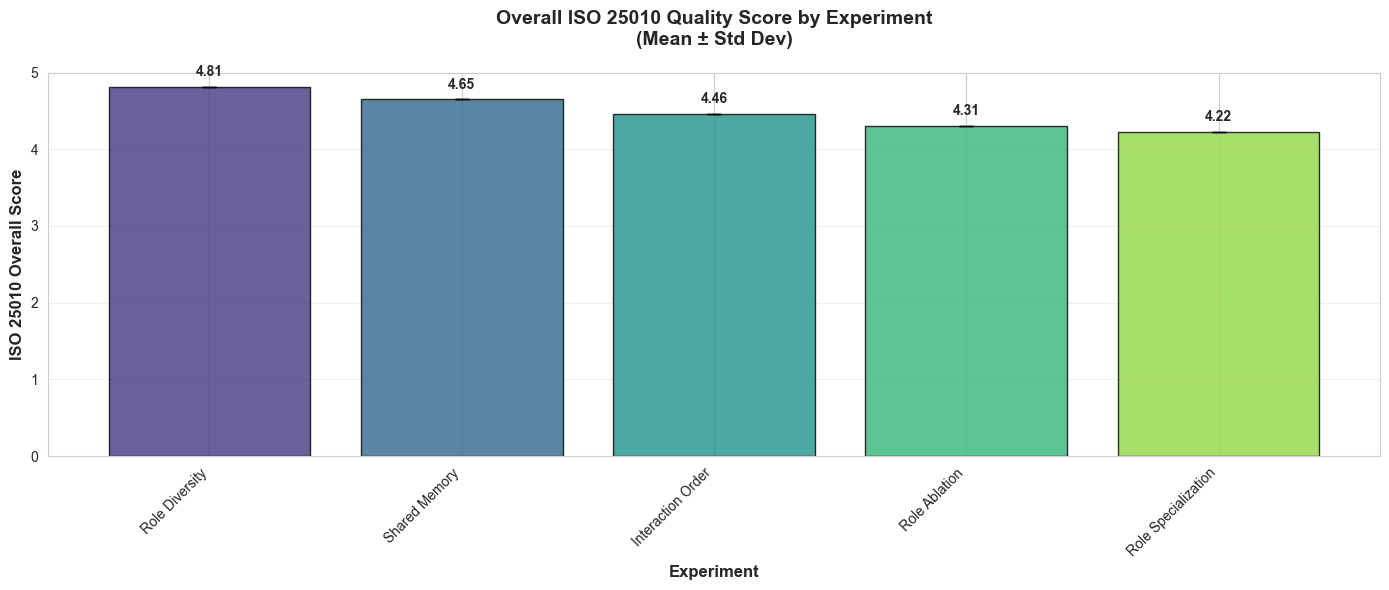

📊 Best performing experiment (ISO Overall): Role Diversity with score 4.810


In [4]:
# 4.1 Bar Chart: Overall ISO Score by Experiment
fig, ax = plt.subplots(figsize=(14, 6))

experiment_means = metrics_df.groupby('experiment')['iso_overall'].mean().sort_values(ascending=False)
experiment_stds = metrics_df.groupby('experiment')['iso_overall'].std()

colors = sns.color_palette("viridis", len(experiment_means))
bars = ax.bar(range(len(experiment_means)), experiment_means.values, 
              yerr=experiment_stds.values, capsize=5, color=colors, alpha=0.8, edgecolor='black')

ax.set_xticks(range(len(experiment_means)))
ax.set_xticklabels(experiment_means.index, rotation=45, ha='right')
ax.set_ylabel('ISO 25010 Overall Score', fontsize=12, fontweight='bold')
ax.set_xlabel('Experiment', fontsize=12, fontweight='bold')
ax.set_title('Overall ISO 25010 Quality Score by Experiment\n(Mean ± Std Dev)', 
             fontsize=14, fontweight='bold', pad=20)
ax.grid(axis='y', alpha=0.3)
ax.set_ylim(0, 5)

# Add value labels on bars
for i, (bar, val, std) in enumerate(zip(bars, experiment_means.values, experiment_stds.values)):
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2., height + std + 0.1,
            f'{val:.2f}', ha='center', va='bottom', fontweight='bold', fontsize=10)

plt.tight_layout()
plt.show()

print("📊 Best performing experiment (ISO Overall):", experiment_means.idxmax(), 
      f"with score {experiment_means.max():.3f}")

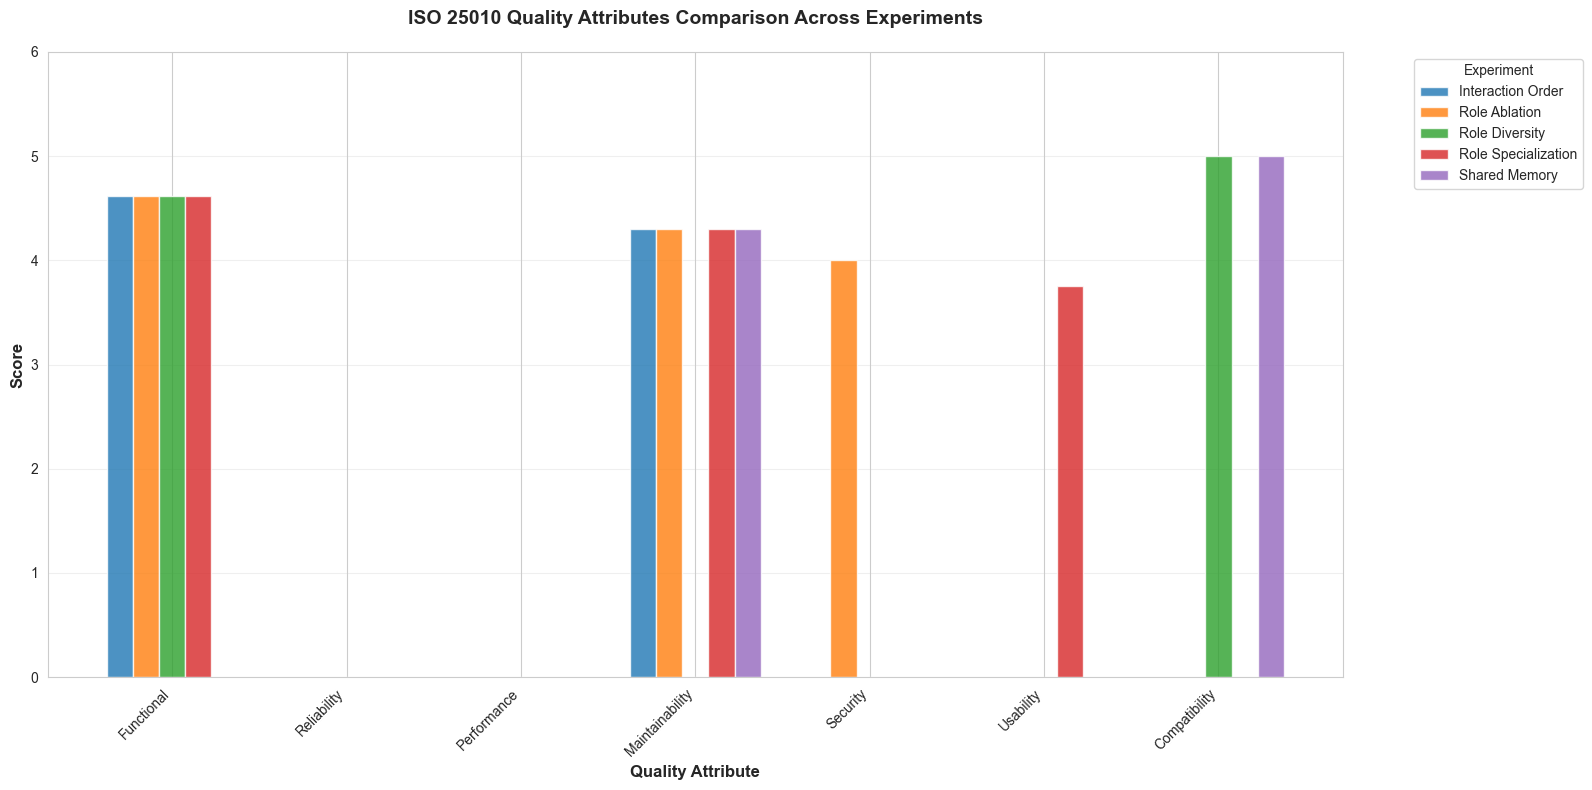

In [5]:
# 4.2 Grouped Bar Chart: ISO 25010 Quality Attributes
fig, ax = plt.subplots(figsize=(16, 8))

# Prepare data
attributes = ['Functional', 'Reliability', 'Performance', 'Maintainability', 'Security', 'Usability', 'Compatibility']
iso_cols = ['iso_functional', 'iso_reliability', 'iso_performance', 'iso_maintainability', 
            'iso_security', 'iso_usability', 'iso_compatibility']

exp_means = metrics_df.groupby('experiment')[iso_cols].mean()

# Set up bar positions
x = np.arange(len(attributes))
width = 0.15
experiments = exp_means.index

# Create bars
for i, exp in enumerate(experiments):
    offset = (i - len(experiments)/2) * width + width/2
    values = exp_means.loc[exp].values
    ax.bar(x + offset, values, width, label=exp, alpha=0.8)

ax.set_ylabel('Score', fontsize=12, fontweight='bold')
ax.set_xlabel('Quality Attribute', fontsize=12, fontweight='bold')
ax.set_title('ISO 25010 Quality Attributes Comparison Across Experiments', 
             fontsize=14, fontweight='bold', pad=20)
ax.set_xticks(x)
ax.set_xticklabels(attributes, rotation=45, ha='right')
ax.legend(title='Experiment', bbox_to_anchor=(1.05, 1), loc='upper left')
ax.grid(axis='y', alpha=0.3)
ax.set_ylim(0, 6)

plt.tight_layout()
plt.show()

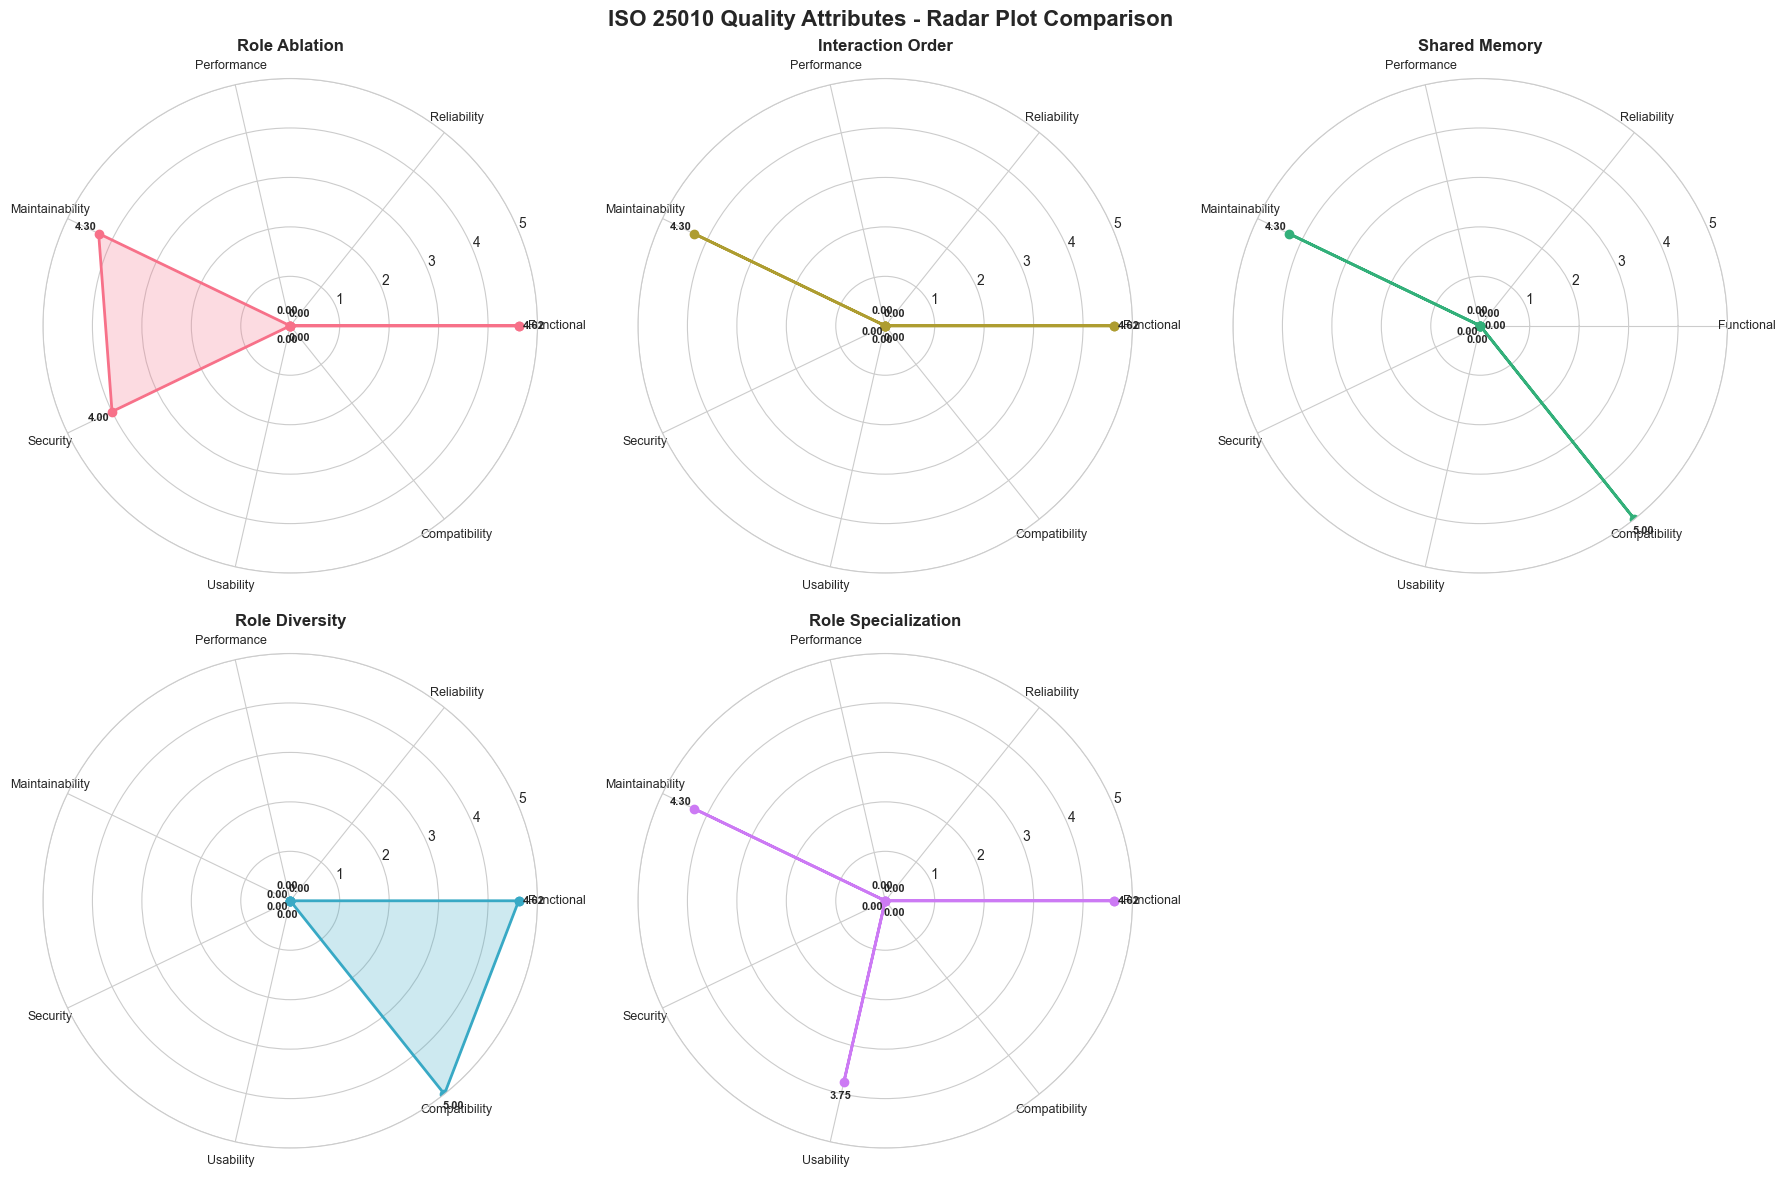

In [6]:
# 4.3 Spider/Radar Plot: Multi-dimensional Quality Comparison
from math import pi

fig, axes = plt.subplots(2, 3, figsize=(18, 12), subplot_kw=dict(projection='polar'))
axes = axes.flatten()

# Prepare data for radar charts
categories = ['Functional', 'Reliability', 'Performance', 'Maintainability', 'Security', 'Usability', 'Compatibility']
N = len(categories)

angles = [n / float(N) * 2 * pi for n in range(N)]
angles += angles[:1]

for idx, exp in enumerate(experiments_data.keys()):
    ax = axes[idx]
    
    # Get mean values for this experiment
    exp_data = metrics_df[metrics_df['experiment'] == exp]
    values = exp_data[iso_cols].mean().tolist()
    values += values[:1]
    
    # Plot
    ax.plot(angles, values, 'o-', linewidth=2, label=exp, color=sns.color_palette("husl", 5)[idx])
    ax.fill(angles, values, alpha=0.25, color=sns.color_palette("husl", 5)[idx])
    ax.set_xticks(angles[:-1])
    ax.set_xticklabels(categories, size=9)
    ax.set_ylim(0, 5)
    ax.set_title(exp, size=12, fontweight='bold', pad=20)
    ax.grid(True)
    
    # Add values on plot
    for angle, value, label in zip(angles[:-1], values[:-1], categories):
        ax.text(angle, value + 0.3, f'{value:.2f}', ha='center', va='center', 
                fontsize=8, fontweight='bold')

# Hide extra subplot
axes[-1].axis('off')

plt.suptitle('ISO 25010 Quality Attributes - Radar Plot Comparison', 
             fontsize=16, fontweight='bold', y=0.98)
plt.tight_layout()
plt.show()

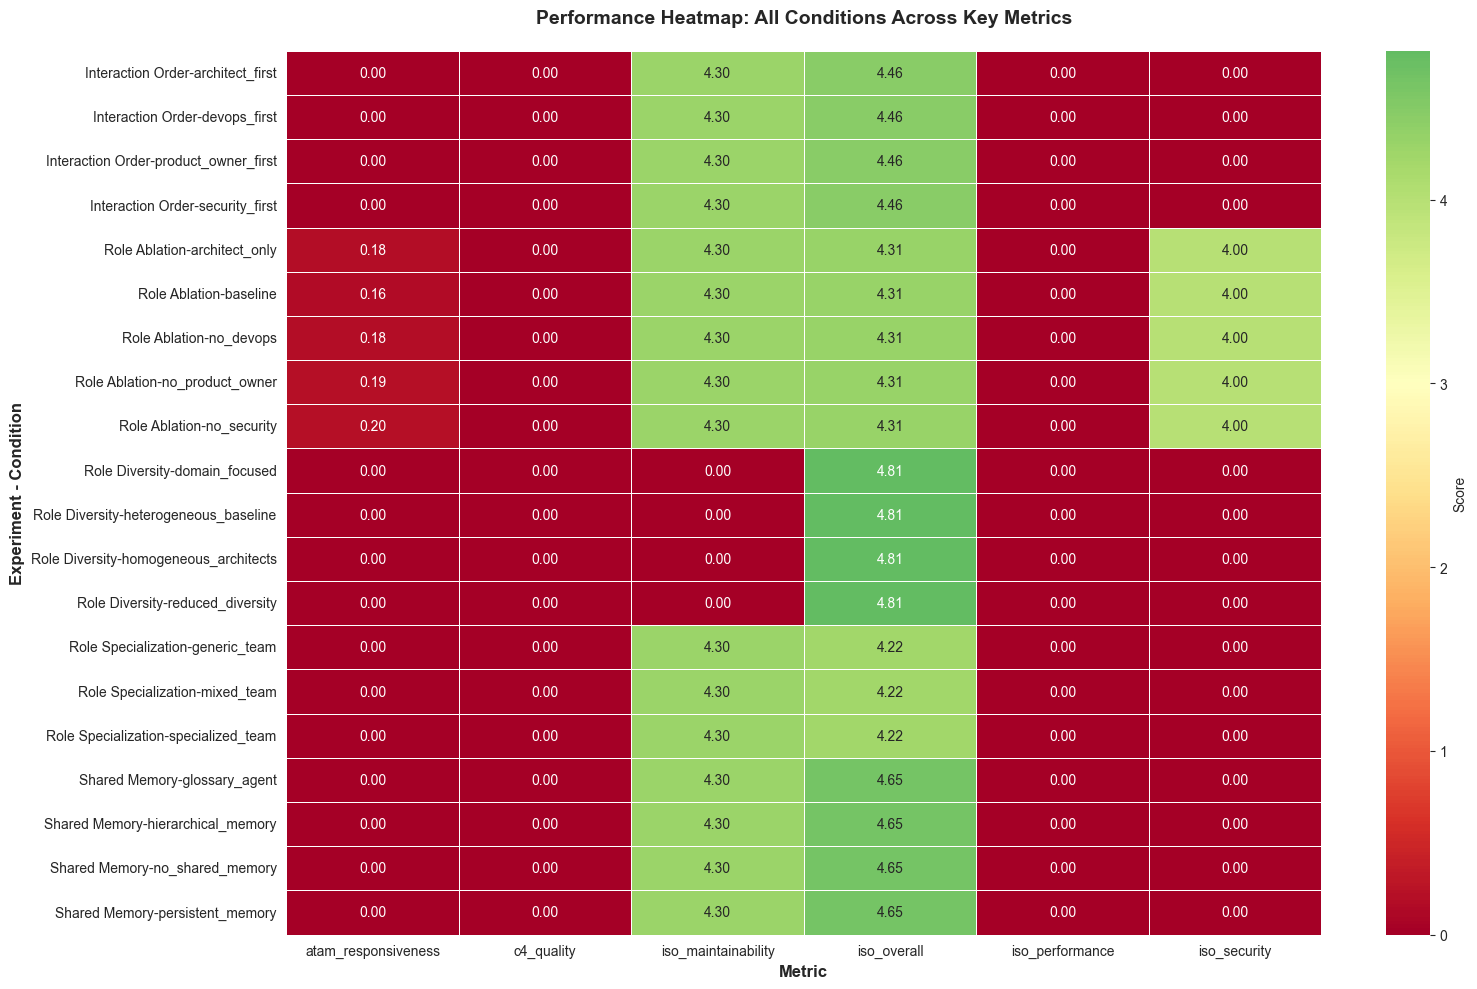

In [7]:
# 4.4 Heatmap: Condition Performance Across Metrics
fig, ax = plt.subplots(figsize=(16, 10))

# Prepare pivot table
heatmap_data = metrics_df.pivot_table(
    index=['experiment', 'condition'],
    values=['iso_overall', 'atam_responsiveness', 'c4_quality', 
            'iso_performance', 'iso_security', 'iso_maintainability'],
    aggfunc='mean'
).round(2)

# Create heatmap
sns.heatmap(heatmap_data, annot=True, fmt='.2f', cmap='RdYlGn', center=3,
            linewidths=0.5, cbar_kws={'label': 'Score'}, ax=ax)

ax.set_title('Performance Heatmap: All Conditions Across Key Metrics', 
             fontsize=14, fontweight='bold', pad=20)
ax.set_xlabel('Metric', fontsize=12, fontweight='bold')
ax.set_ylabel('Experiment - Condition', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()

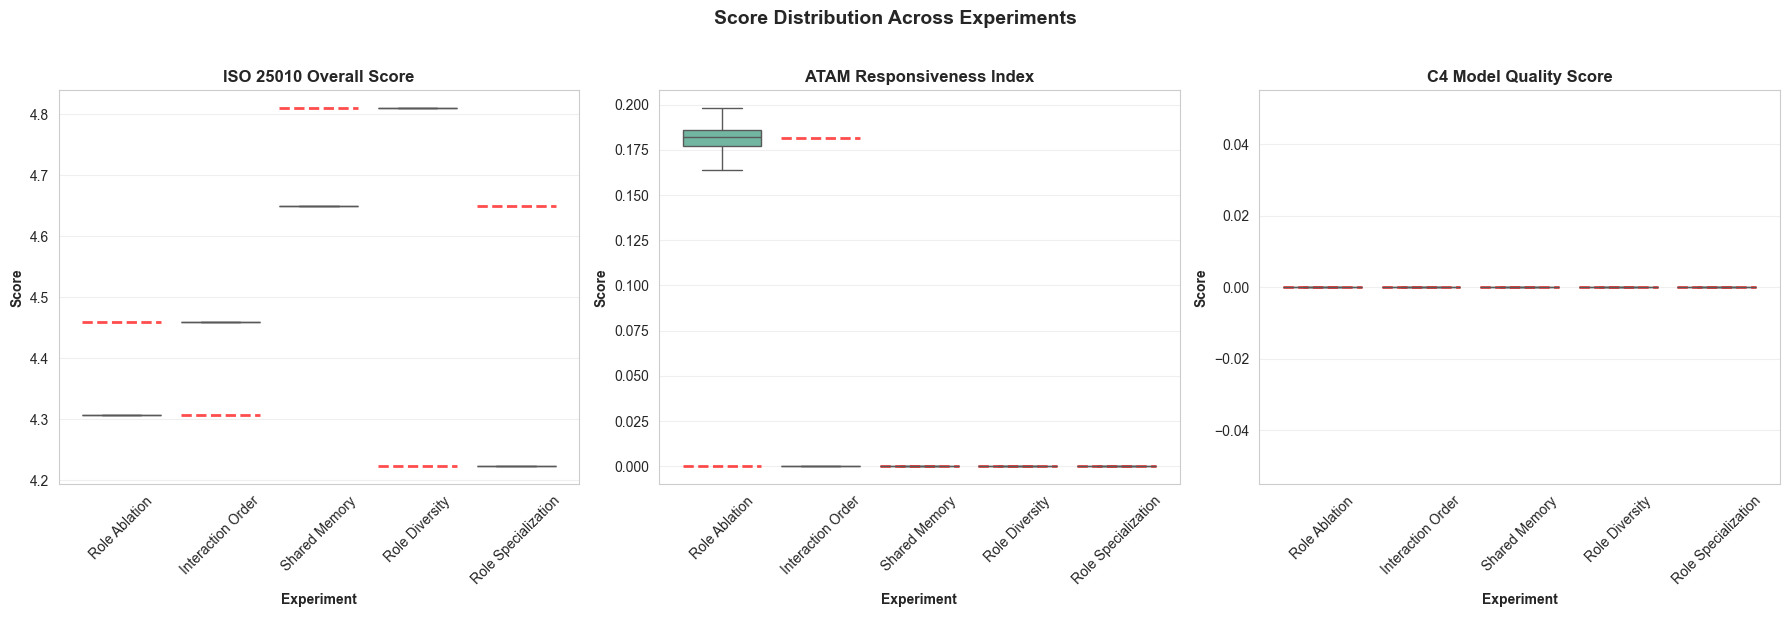

In [8]:
# 4.5 Box Plots: Distribution of Scores by Experiment
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

metrics_to_plot = [
    ('iso_overall', 'ISO 25010 Overall Score'),
    ('atam_responsiveness', 'ATAM Responsiveness Index'),
    ('c4_quality', 'C4 Model Quality Score')
]

for ax, (metric, title) in zip(axes, metrics_to_plot):
    sns.boxplot(data=metrics_df, x='experiment', y=metric, ax=ax, palette='Set2')
    ax.set_title(title, fontsize=12, fontweight='bold')
    ax.set_xlabel('Experiment', fontsize=10, fontweight='bold')
    ax.set_ylabel('Score', fontsize=10, fontweight='bold')
    ax.tick_params(axis='x', rotation=45)
    ax.grid(axis='y', alpha=0.3)
    
    # Add mean line
    means = metrics_df.groupby('experiment')[metric].mean()
    for i, (exp, mean_val) in enumerate(means.items()):
        ax.hlines(mean_val, i-0.4, i+0.4, colors='red', linestyles='dashed', linewidth=2, alpha=0.7)

plt.suptitle('Score Distribution Across Experiments', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

## 5. Statistical Analysis & Key Findings

In [17]:
# 5.1 Statistical Significance Testing (ANOVA)
from scipy import stats

print("="*80)
print("📊 STATISTICAL SIGNIFICANCE ANALYSIS (One-Way ANOVA)")
print("="*80)
print("\nTesting if there are significant differences between experiments...\n")

metrics_to_test = ['iso_overall', 'atam_responsiveness', 'c4_quality', 
                   'iso_performance', 'iso_security']

anova_results = []

for metric in metrics_to_test:
    # Prepare groups
    groups = [group[metric].values for name, group in metrics_df.groupby('experiment')]
    
    # Perform ANOVA
    f_stat, p_value = stats.f_oneway(*groups)
    
    anova_results.append({
        'Metric': metric.replace('_', ' ').title(),
        'F-Statistic': f_stat,
        'P-Value': p_value,
        'Significant': '✓' if p_value < 0.05 else '✗'
    })
    
    print(f"{metric.replace('_', ' ').title():<30} F={f_stat:.3f}, p={p_value:.4f} {'✓ SIGNIFICANT' if p_value < 0.05 else '✗ Not significant'}")

print("\n" + "="*80)
print("Note: p < 0.05 indicates statistically significant differences between experiments")
print("="*80 + "\n")

📊 STATISTICAL SIGNIFICANCE ANALYSIS (One-Way ANOVA)

Testing if there are significant differences between experiments...

Iso Overall                    F=0.847, p=0.5172 ✗ Not significant
Atam Responsiveness            F=1.136, p=0.3770 ✗ Not significant
C4 Quality                     F=1.706, p=0.2010 ✗ Not significant
Iso Performance                F=0.847, p=0.5172 ✗ Not significant
Iso Security                   F=nan, p=nan ✗ Not significant

Note: p < 0.05 indicates statistically significant differences between experiments



In [18]:
# 5.2 Identify Standout Findings
print("="*80)
print("🔍 KEY FINDINGS & STANDOUT RESULTS")
print("="*80)

# 1. Best performing experiment overall
best_exp = metrics_df.groupby('experiment')['composite_score'].mean().idxmax()
best_score = metrics_df.groupby('experiment')['composite_score'].mean().max()
print(f"\n1. BEST OVERALL EXPERIMENT: {best_exp}")
print(f"   Composite Score: {best_score:.3f}")

# 2. Most consistent experiment (lowest std dev)
consistency = metrics_df.groupby('experiment')['iso_overall'].std().sort_values()
print(f"\n2. MOST CONSISTENT RESULTS: {consistency.index[0]}")
print(f"   Standard Deviation: {consistency.values[0]:.3f}")

# 3. Performance standouts
perf_leader = metrics_df.groupby('experiment')['iso_performance'].mean().idxmax()
perf_score = metrics_df.groupby('experiment')['iso_performance'].mean().max()
print(f"\n3. BEST PERFORMANCE EFFICIENCY: {perf_leader}")
print(f"   Performance Score: {perf_score:.3f}")

# 4. Security standouts
sec_leader = metrics_df.groupby('experiment')['iso_security'].mean().idxmax()
sec_score = metrics_df.groupby('experiment')['iso_security'].mean().max()
print(f"\n4. BEST SECURITY: {sec_leader}")
print(f"   Security Score: {sec_score:.3f}")

# 5. Largest variance between conditions
variance_analysis = metrics_df.groupby('experiment')['iso_overall'].agg(['min', 'max', lambda x: x.max() - x.min()])
variance_analysis.columns = ['Min', 'Max', 'Range']
variance_analysis = variance_analysis.sort_values('Range', ascending=False)
print(f"\n5. LARGEST VARIATION BETWEEN CONDITIONS:")
print(variance_analysis.head(3).to_string())

# 6. Correlation analysis
print(f"\n6. METRIC CORRELATIONS:")
correlation_metrics = ['iso_overall', 'atam_responsiveness', 'c4_quality', 
                       'iso_performance', 'iso_security']
corr_matrix = metrics_df[correlation_metrics].corr().round(3)
print("\nHighest positive correlations:")
corr_pairs = []
for i in range(len(correlation_metrics)):
    for j in range(i+1, len(correlation_metrics)):
        corr_pairs.append((correlation_metrics[i], correlation_metrics[j], corr_matrix.iloc[i, j]))
corr_pairs.sort(key=lambda x: abs(x[2]), reverse=True)
for metric1, metric2, corr in corr_pairs[:3]:
    print(f"   {metric1} ↔ {metric2}: {corr:.3f}")

# 7. Worst performing aspect
worst_attributes = metrics_df[iso_cols].mean().sort_values()
print(f"\n7. WEAKEST QUALITY ATTRIBUTES (Overall):")
for i in range(min(3, len(worst_attributes))):
    print(f"   {worst_attributes.index[i].replace('iso_', '').replace('_', ' ').title()}: {worst_attributes.values[i]:.3f}")

print("\n" + "="*80)

🔍 KEY FINDINGS & STANDOUT RESULTS

1. BEST OVERALL EXPERIMENT: Role Specialization
   Composite Score: 2.129

2. MOST CONSISTENT RESULTS: Shared Memory
   Standard Deviation: 0.015

3. BEST PERFORMANCE EFFICIENCY: Role Specialization
   Performance Score: 1.804

4. BEST SECURITY: Interaction Order
   Security Score: 4.000

5. LARGEST VARIATION BETWEEN CONDITIONS:
                          Min       Max     Range
experiment                                       
Role Ablation        3.981429  4.132286  0.150857
Role Diversity       3.995714  4.054429  0.058714
Role Specialization  4.048143  4.092571  0.044429

6. METRIC CORRELATIONS:

Highest positive correlations:
   iso_overall ↔ iso_performance: 1.000
   iso_overall ↔ atam_responsiveness: 0.276
   iso_overall ↔ c4_quality: -0.199

7. WEAKEST QUALITY ATTRIBUTES (Overall):
   Performance: 1.627
   Usability: 3.750
   Security: 4.000



## 6. Detailed Condition-Level Analysis

In [11]:
# Analyze each experiment's conditions
for exp_name in experiments_data.keys():
    print("="*80)
    print(f"📋 {exp_name.upper()} - CONDITION COMPARISON")
    print("="*80)
    
    exp_df = metrics_df[metrics_df['experiment'] == exp_name].copy()
    
    if len(exp_df) == 0:
        print("No data available\n")
        continue
    
    # Sort by composite score
    exp_df = exp_df.sort_values('composite_score', ascending=False)
    
    # Display key metrics
    display_cols = ['condition', 'iso_overall', 'atam_responsiveness', 'c4_quality', 
                    'iso_performance', 'iso_security', 'composite_score']
    
    print(exp_df[display_cols].round(3).to_string(index=False))
    
    # Highlight best and worst
    best_cond = exp_df.iloc[0]
    worst_cond = exp_df.iloc[-1]
    
    print(f"\n✓ BEST: {best_cond['condition']} (Composite: {best_cond['composite_score']:.3f})")
    print(f"✗ WORST: {worst_cond['condition']} (Composite: {worst_cond['composite_score']:.3f})")
    print(f"Δ DIFFERENCE: {(best_cond['composite_score'] - worst_cond['composite_score']):.3f}")
    print()

📋 ROLE ABLATION - CONDITION COMPARISON
       condition  iso_overall  atam_responsiveness  c4_quality  iso_performance  iso_security  composite_score
     no_security        4.307                0.198           0                0           4.0            2.252
no_product_owner        4.307                0.186           0                0           4.0            2.246
       no_devops        4.307                0.182           0                0           4.0            2.244
  architect_only        4.307                0.177           0                0           4.0            2.242
        baseline        4.307                0.164           0                0           4.0            2.235

✓ BEST: no_security (Composite: 2.252)
✗ WORST: baseline (Composite: 2.235)
Δ DIFFERENCE: 0.017

📋 INTERACTION ORDER - CONDITION COMPARISON
          condition  iso_overall  atam_responsiveness  c4_quality  iso_performance  iso_security  composite_score
    architect_first         4.46        

## 7. Export Results Summary